# House Stage 1: does removing partisan lean from Model B help the ensemble?

Model B, the fundamentals model blended at 15% into `house_ensemble_ab_85_15`, includes `partisan_lean`, which Model A already uses. This notebook asks whether a **lean-free B** adds information that complements A better. It compares:

| model | prediction | role |
|---|---|---|
| **A** | Model A (polling), unchanged: `partisan_lean + gen_margin_raw + inc_signed` (fixed +2.5) `+ partisan_lean:inc_signed + gb_momentum_30d_raw` | reference |
| **AB-15** | 0.85 A + 0.15 B; B = `partisan_lean + fundraising_advantage + pres_party_signed:is_midterm + pres_party_signed:cpi_region_log_yoy` | baseline (`house_ensemble_ab_85_15`) |
| **AB-NoLean-15** | 0.85 A + 0.15 B-NoLean; B-NoLean = `fundraising_advantage + rel_state_college + pres_party_signed:is_midterm + pres_party_signed:cpi_region_log_yoy` | alternative |
| **Shrink-15** | A − 0.15 × (A's partisan-lean terms) = 0.85 A + 0.15 (A without its lean terms) | diagnostic only |

**Shrink-15** is a benchmark for one specific explanation. Blending A at 0.85 with a lean-free model scales A's lean contribution (`partisan_lean` and `partisan_lean:inc_signed`) by 0.85. Shrink-15 applies exactly that shrinkage and nothing else: no fundraising, no college, no national fundamentals. If AB-NoLean-15 does no better than Shrink-15, its gain is structural shrinkage rather than new information.

**Design:**

- **Fixed specification:** the two established configurations in `house.stage1` are used as is. B-NoLean is defined here only, the blend weight stays fixed at 0.15, and nothing is tuned or selected.
- **Estimation:** every model is fit by equal-year WLS (`stage1.fit_predict`), on expanding windows from 2006 through the election before each eval year.
- **Matched samples:** in each window all models fit and score exactly the same district-years (asserted).
- **Evaluation years:** 2018, 2020, 2022, and 2024. **2024 is not an untouched holdout here:** `01_reg_final_2024_holdout.ipynb` already scored it, so it is development evidence like the other years.
- **Subsets:** valid targets (observed, non-imputed, D-vs-R race types), ex-ante competitive (|lean + eve-of-election generic ballot| ≤ 10), and ex-post competitive (|actual two-party margin| ≤ 7.5).
- **Residuals:** actual − predicted, in D − R points. Positive means Democrats outperformed the model.
- **Averages:** *pooled* averages weight every race equally; *equal-year* averages are the mean of the four per-year values.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats

# The repository root is the first folder up from here that holds pyproject.toml, so this works at any depth
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))  # repository root, for experiments.house
import house.regression as hr
from experiments.house import evaluation, tracking
from house import stage1
from house.regression.schema import KEY

with warnings.catch_warnings(action="ignore"):  # loading warns about known optional-column gaps
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, 2006-2026
    targets = hr.load_targets()        # data/processed/house/targets.csv, 2006-2024

## Settings and models

In [2]:
TARGET = stage1.TARGET
EVAL_YEARS = [2018, 2020, 2022, 2024]  # each fit on 2006 through the election before it
EVAL_RACE_TYPES = ["dr", "dr_multi", "dr_jungle", "dr_rcv", "dr_writein"]
EX_ANTE_THRESHOLD = 10
EX_POST_THRESHOLD = 7.5
COMPETITIVE = {
    "competitive_ex_ante": ("partisan_lean + gb_margin_2p_norm", EX_ANTE_THRESHOLD),  # known before the election
    "competitive_ex_post": ("margin_2p_norm", EX_POST_THRESHOLD),                     # the observed margin
}
SECTIONS = {"EX_ANTE": "competitive_ex_ante", "EX_POST": "competitive_ex_post", "ALL": "valid"}  # priority order
WEIGHT_B = 0.15  # fixed; not tuned

# The established configurations, used unchanged
assert stage1.HOUSE_ENSEMBLE_AB_85_15.components == ((stage1.MODEL_A, 0.85), (stage1.MODEL_B, 0.15))
assert stage1.HOUSE_MODEL_A.components == ((stage1.MODEL_A, 1.0),)

# The alternative, defined here only: B without partisan_lean, with within-state relative college share
MODEL_B_NOLEAN = stage1.Component(
    "B_nolean",
    f"{TARGET} ~ fundraising_advantage + rel_state_college + pres_party_signed:is_midterm"
    " + pres_party_signed:cpi_region_log_yoy",
)
AB_NOLEAN_15 = stage1.Stage1Config("ab_nolean_15", ((stage1.MODEL_A, 1 - WEIGHT_B), (MODEL_B_NOLEAN, WEIGHT_B)))
CONFIGS = {"AB-15": stage1.HOUSE_ENSEMBLE_AB_85_15, "AB-NoLean-15": AB_NOLEAN_15}
assert "partisan_lean" not in MODEL_B_NOLEAN.formula

for label, config in CONFIGS.items():
    print(label, [(c.name, w) for c, w in config.components])
    for component, _ in config.components:
        print(f"    {component.name:15s} {component.formula}   fixed: {dict(component.fixed) or 'none'}")

AB-15 [('A_polling', 0.85), ('B_fundamentals', 0.15)]
    A_polling       adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + inc_signed + partisan_lean:inc_signed + gb_momentum_30d_raw   fixed: {'inc_signed': 2.5}
    B_fundamentals  adj_margin_2p_norm ~ partisan_lean + fundraising_advantage + pres_party_signed:is_midterm + pres_party_signed:cpi_region_log_yoy   fixed: none
AB-NoLean-15 [('A_polling', 0.85), ('B_nolean', 0.15)]
    A_polling       adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + inc_signed + partisan_lean:inc_signed + gb_momentum_30d_raw   fixed: {'inc_signed': 2.5}
    B_nolean        adj_margin_2p_norm ~ fundraising_advantage + rel_state_college + pres_party_signed:is_midterm + pres_party_signed:cpi_region_log_yoy   fixed: none


## Rolling fits

Both ensembles are fit in every window. Model A appears in each, so its predictions must agree, and every component must use the same training and evaluation rows. Both conditions are asserted.

In [3]:
with warnings.catch_warnings(action="ignore"):
    rolling = {label: stage1.rolling_predictions(config, EVAL_YEARS, predictors=predictors, targets=targets)
               for label, config in CONFIGS.items()}

for year in EVAL_YEARS:
    base, alt = rolling["AB-15"][year], rolling["AB-NoLean-15"][year]
    runs = [*base.components.values(), *alt.components.values()]
    assert len({(r.counts["train_rows_hash"], r.counts["eval_rows_hash"]) for r in runs}) == 1, year
    assert base.predictions[KEY].equals(alt.predictions[KEY]), year
    assert np.array_equal(base.predictions["prediction_A_polling"], alt.predictions["prediction_A_polling"]), year
    print(year, "trained on", runs[0].config["train_years"][0], "-", runs[0].config["train_years"][-1],
          "| train rows", runs[0].counts["n_train"], "| eval rows", len(base.predictions))

2018 trained on 2006 - 2016 | train rows 2282 | eval rows 393
2020 trained on 2006 - 2018 | train rows 2675 | eval rows 408
2022 trained on 2006 - 2020 | train rows 3083 | eval rows 399
2024 trained on 2006 - 2022 | train rows 3482 | eval rows 398


## The shrinkage-only benchmark

In each window, A's lean contribution for a district is $\hat\beta_P P + \hat\beta_{PI}\,(P\cdot I)$, with A's own fitted coefficients for that window. Shrink-15 subtracts 15% of it from A's prediction and changes nothing else.

In [4]:
def lean_contribution(result, rows):
    # Model A's partisan-lean terms for `rows`, with the window's fitted A coefficients
    params = result.components["A_polling"].model.params
    return (params["partisan_lean"] * rows["partisan_lean"]
            + params["partisan_lean:inc_signed"] * rows["partisan_lean"] * rows["inc_signed"])


MODELS = ["A", "AB-15", "AB-NoLean-15", "Shrink-15", "B", "B-NoLean"]
ENSEMBLES = ["AB-15", "AB-NoLean-15", "Shrink-15"]
frames = []
for year in EVAL_YEARS:
    base, alt = rolling["AB-15"][year].predictions, rolling["AB-NoLean-15"][year].predictions
    rows = base[KEY].merge(predictors, on=KEY, how="left", validate="one_to_one")
    frames.append(base[KEY].assign(**{
        "A": base["prediction_A_polling"],
        "AB-15": base["prediction"],
        "AB-NoLean-15": alt["prediction"],
        "Shrink-15": base["prediction_A_polling"] - WEIGHT_B * lean_contribution(rolling["AB-15"][year], rows),
        "B": base["prediction_B_fundamentals"],
        "B-NoLean": alt["prediction_B_nolean"],
    }))
predictions = pd.concat(frames, ignore_index=True)

# Score every model like a single model, on the valid targets
scores = {m: evaluation.evaluate_predictions(predictions[KEY].assign(prediction=predictions[m]), targets, predictors,
                                             TARGET, competitive=COMPETITIVE, race_types=EVAL_RACE_TYPES)
          for m in MODELS}
metrics = {m: s[0] for m, s in scores.items()}
scored = {m: s[2] for m, s in scores.items()}
assert all(scored[m][KEY].equals(scored["A"][KEY]) for m in MODELS)  # identical valid district-years

# One row per valid district-year; PRED and RESID hold each model's prediction and residual on the same rows
races = scored["A"][[*KEY, "actual_margin", "competitive_ex_ante", "competitive_ex_post"]].merge(
    predictors[[*KEY, "partisan_lean", "inc_signed"]], on=KEY, how="left", validate="one_to_one")
PRED = pd.DataFrame({m: scored[m]["predicted_margin"].to_numpy() for m in MODELS}, index=races.index)
RESID = races["actual_margin"].to_numpy()[:, None] - PRED
MASKS = {"EX_ANTE": races["competitive_ex_ante"], "EX_POST": races["competitive_ex_post"],
         "ALL": pd.Series(True, index=races.index)}
scores["A"][1]  # coverage: districts per eval year by exclusion reason, and the subset sizes

,n_districts,missing_target,imputed_target,no_prediction,n_valid,competitive_ex_ante,competitive_ex_ante_undetermined,competitive_ex_post,competitive_ex_post_undetermined
year,,,,,,,,,
2018,435,0,42,0,393,100,0,68,0
2020,435,0,27,0,408,92,0,61,0
2022,435,0,36,0,399,81,0,52,0
2024,435,0,37,0,398,80,0,49,0
all,1740,0,142,0,1598,353,0,230,0


## 1. Performance

MAE and winner accuracy for each subset, per eval year, pooled over the four years, and as the equal-year mean. Δ is model − A on the same races. ✓ marks an improvement over A and ✗ a regression. Shrink-15 is diagnostic only. B and B-NoLean are the standalone fundamentals models, never used alone.

In [5]:
METRICS = ["n", "mae", "rmse", "accuracy_pct", "missed_races"]
DELTAS = ["mae", "accuracy_pct", "missed_races"]


def performance(period):
    # model x (section, metric); period is an eval year, "pooled", or "equal-year mean"
    def values(m, subset):
        if period == "pooled":
            return metrics[m].loc[(subset, "all")]
        if period == "equal-year mean":
            return sum(metrics[m].loc[(subset, y)] for y in EVAL_YEARS) / len(EVAL_YEARS)
        return metrics[m].loc[(subset, period)]

    rows = {}
    for m in MODELS:
        row = {}
        for section, subset in SECTIONS.items():
            v, a = values(m, subset), values("A", subset)
            row |= {(section, k): v[k] for k in METRICS}
            if m != "A":
                row |= {(section, f"Δ{k}"): v[k] - a[k] for k in DELTAS}
        rows[m] = row
    return pd.DataFrame.from_dict(rows, orient="index")


for period in ["pooled", "equal-year mean"]:
    display(Markdown(f"### {period.capitalize()}, 2018–2024"))
    display(tracking.style_best_of(performance(period)))

### Pooled, 2018–2024

### Equal-year mean, 2018–2024

In [6]:
by_year = pd.concat({year: performance(year) for year in EVAL_YEARS}, names=["eval_year", "model"]).swaplevel()
by_year = by_year.reindex([(m, y) for m in MODELS for y in EVAL_YEARS])
display(Markdown("### Per eval year"))
tracking.style_best_of(by_year)

### Per eval year

## 2. Winner calls fixed and broken relative to A

A call is **fixed** when the model is right and A was wrong, and **broken** when A was right and the model is wrong. Net = fixed − broken: the change in correct calls. A race counts in every subset it belongs to.

In [7]:
def correct(m):
    return pd.Series(np.sign(PRED[m]) == np.sign(races["actual_margin"]), index=races.index)


flip_rows = {}
for m in ENSEMBLES + ["B", "B-NoLean"]:
    fixed, broken = correct(m) & ~correct("A"), ~correct(m) & correct("A")
    for section, mask in MASKS.items():
        for year in [*EVAL_YEARS, "pooled"]:
            in_year = mask if year == "pooled" else mask & (races["year"] == year)
            f, b = int((fixed & in_year).sum()), int((broken & in_year).sum())
            flip_rows[(m, year)] = flip_rows.get((m, year), {}) | {(section, "fixed"): f, (section, "broken"): b,
                                                                    (section, "net"): f - b}
flips = pd.DataFrame.from_dict(flip_rows, orient="index").rename_axis(["model", "eval_year"])
flips.style.map(lambda v: f"color: {tracking.GOOD}" if v > 0 else f"color: {tracking.BAD}" if v < 0 else "",
                subset=[c for c in flips.columns if c[1] == "net"])

In [8]:
# Every competitive race where an ensemble's call differs from A's
competitive = races["competitive_ex_ante"] | races["competitive_ex_post"]
changed = []
for m in ENSEMBLES:
    differs = competitive & (np.sign(PRED[m]) != np.sign(PRED["A"]))
    for i in races.index[differs]:
        r = races.loc[i]
        changed.append({"model": m, "year": r["year"], "district": evaluation.district_label(r["state"], r["district"]),
                        "ex_ante": r["competitive_ex_ante"], "ex_post": r["competitive_ex_post"],
                        "lean": r["partisan_lean"], "actual": r["actual_margin"], "A": PRED.loc[i, "A"],
                        "model_pred": PRED.loc[i, m], "verdict": "fixed" if correct(m)[i] else "broken"})
changed = pd.DataFrame(changed)
changed.style.format({"lean": "{:+.1f}", "actual": "{:+.1f}", "A": "{:+.1f}", "model_pred": "{:+.1f}"}).map(
    lambda v: f"color: {tracking.GOOD}" if v == "fixed" else f"color: {tracking.BAD}" if v == "broken" else "",
    subset=["verdict"])

,model,year,district,ex_ante,ex_post,lean,actual,A,model_pred,verdict
0,AB-15,2018,NE-02,True,True,-6.2,-2.0,-0.7,+0.0,broken
1,AB-15,2018,NJ-03,True,True,-6.3,+1.3,-0.8,+0.2,fixed
2,AB-15,2018,NY-19,True,True,-6.4,+5.3,-1.0,+0.4,fixed
3,AB-15,2018,VA-02,True,True,-5.9,+2.2,-0.4,+0.3,fixed
4,AB-15,2022,CO-08,True,True,-0.9,+0.7,+0.0,-0.3,broken
5,AB-15,2022,NY-19,True,True,-0.9,-1.6,+0.1,-0.3,fixed
6,AB-NoLean-15,2018,NE-02,True,True,-6.2,-2.0,-0.7,+0.5,broken
7,AB-NoLean-15,2018,NJ-03,True,True,-6.3,+1.3,-0.8,+0.5,fixed
8,AB-NoLean-15,2018,NY-19,True,True,-6.4,+5.3,-1.0,+1.2,fixed
9,AB-NoLean-15,2018,TX-07,True,True,-7.0,+5.1,-1.6,+0.8,fixed


## 3. Standalone Model B and coefficient stability

The coefficients in each window (coef, with the WLS standard error beneath in the second table), and their spread across the four windows. A stable fundamentals model keeps its signs and magnitudes as each election is added.

In [9]:
COMPONENTS = {"A": ("AB-15", "A_polling"), "B": ("AB-15", "B_fundamentals"), "B-NoLean": ("AB-NoLean-15", "B_nolean")}


def coefficient_table(model, column):
    label, name = COMPONENTS[model]
    return pd.DataFrame({year: rolling[label][year].components[name].coefficients[column] for year in EVAL_YEARS})


coefs = pd.concat({m: coefficient_table(m, "coef") for m in COMPONENTS}, names=["model", "term"])
spread = pd.DataFrame({"mean": coefs.mean(axis=1), "sd": coefs.std(axis=1), "min": coefs.min(axis=1),
                       "max": coefs.max(axis=1)})
spread["sd/|mean|"] = spread["sd"] / spread["mean"].abs()
spread["sign changes"] = (np.sign(coefs).nunique(axis=1) > 1)
display(Markdown("### Coefficients by eval window, with their spread"))
display(coefs.join(spread).style.format(precision=3))
display(Markdown("### Standard errors by eval window (blank: fixed coefficient)"))
pd.concat({m: coefficient_table(m, "std_err") for m in COMPONENTS}, names=["model", "term"]).round(3)

### Coefficients by eval window, with their spread

### Standard errors by eval window (blank: fixed coefficient)

2018   2020   2022   2024
model    term                                                            
A        Intercept                             0.590  0.544  0.501  0.471
         partisan_lean                         0.010  0.009  0.008  0.007
         gen_margin_raw                        0.104  0.093  0.088  0.085
         partisan_lean:inc_signed              0.015  0.013  0.011  0.010
         gb_momentum_30d_raw                   0.301  0.277  0.261  0.248
         inc_signed                              NaN    NaN    NaN    NaN
B        Intercept                             0.217  0.191  0.175  0.160
         partisan_lean                         0.012  0.011  0.010  0.009
         fundraising_advantage                 0.110  0.101  0.093  0.087
         pres_party_signed:is_midterm          0.342  0.294  0.283  0.276
         pres_party_signed:cpi_region_log_yoy  0.094  0.091  0.087  0.059
B-NoLean Intercept                             0.322  0.294  0.281  0.256
         fundraising_advantage                 0.100  0.095  0.090  0.083
         rel_state_college                     0.035  0.032  0.030  0.027
         pres_party_signed:is_midterm          0.509  0.452  0.453  0.443
         pres_party_signed:cpi_region_log_yoy  0.139  0.139  0.138  0.095

## 4. Residual distributions

Pooled out-of-sample residuals (actual − predicted) for each subset. Skewness and excess kurtosis are 0 for a normal distribution. The `>10`, `>15`, and `>20` columns are the percentage of races whose absolute error exceeds that many points.

In [10]:
def residual_stats(r):
    r = pd.Series(r).astype(float)
    q = r.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    return {"n": len(r), "bias": r.mean(), "mae": r.abs().mean(), "rmse": np.sqrt((r ** 2).mean()), "sd": r.std(),
            "q05": q[0.05], "q25": q[0.25], "median": q[0.5], "q75": q[0.75], "q95": q[0.95],
            "skew": stats.skew(r), "excess_kurtosis": stats.kurtosis(r),
            **{f">{t}": 100 * (r.abs() > t).mean() for t in (10, 15, 20)}}


distribution = pd.DataFrame.from_dict({(section, m): residual_stats(RESID.loc[mask, m])
                                       for section, mask in MASKS.items() for m in MODELS}, orient="index")
distribution.index.names = ["subset", "model"]
distribution.style.format(precision=2).format({"n": "{:.0f}"})

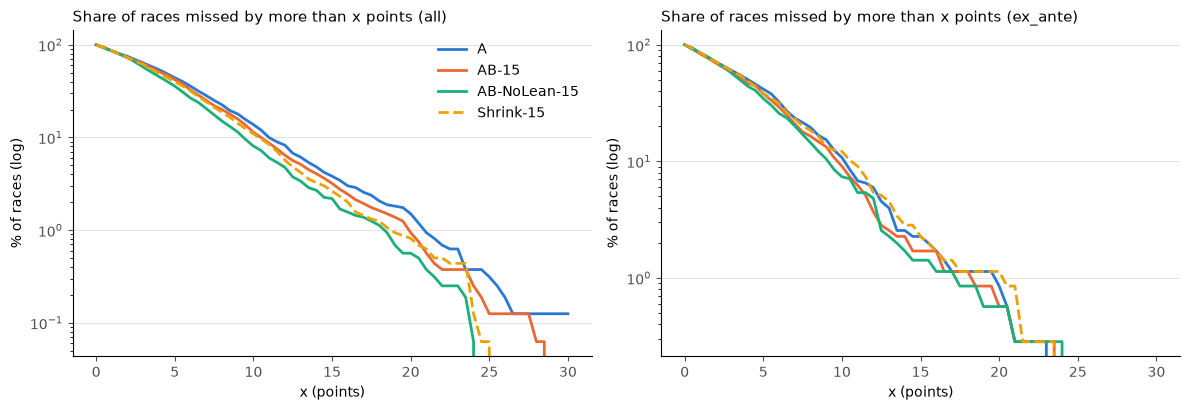

In [11]:
COLORS = {"A": "#2a78d6", "AB-15": "#eb6834", "AB-NoLean-15": "#1baf7a", "Shrink-15": "#eda100"}
STYLES = {"A": "-", "AB-15": "-", "AB-NoLean-15": "-", "Shrink-15": "--"}


def tidy(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors="#52514e")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
thresholds = np.arange(0, 30.5, 0.5)
for ax, section in zip(axes, ["ALL", "EX_ANTE"]):
    for m in COLORS:
        r = RESID.loc[MASKS[section], m].abs()
        ax.plot(thresholds, [100 * (r > t).mean() for t in thresholds], STYLES[m], color=COLORS[m], lw=2, label=m)
    ax.set_yscale("log")
    tidy(ax, f"Share of races missed by more than x points ({section.lower()})", "x (points)", "% of races (log)")
axes[0].legend(frameon=False)
plt.tight_layout()

## 5. Residual correlation: A vs each Model B

A blend helps most when its components' errors are weakly correlated. The pooled correlations include each year's national error, which every model shares. The *within-year* correlations remove each year's mean residual first.

In [12]:
def correlations(rows, within_year):
    r = RESID.loc[rows, ["A", "B", "B-NoLean"]]
    if within_year:
        r = r - r.groupby(races.loc[rows, "year"]).transform("mean")
    return {"n": len(r), "corr(A, B)": r["A"].corr(r["B"]), "corr(A, B-NoLean)": r["A"].corr(r["B-NoLean"]),
            "corr(B, B-NoLean)": r["B"].corr(r["B-NoLean"])}


corr_rows = {}
for section, mask in MASKS.items():
    for year in EVAL_YEARS:
        corr_rows[(section, year)] = correlations(mask & (races["year"] == year), within_year=False)
    corr_rows[(section, "equal-year mean")] = pd.DataFrame([corr_rows[(section, y)] for y in EVAL_YEARS]).mean().to_dict()
    corr_rows[(section, "pooled")] = correlations(mask, within_year=False)
    corr_rows[(section, "pooled, within-year")] = correlations(mask, within_year=True)
pd.DataFrame.from_dict(corr_rows, orient="index").rename_axis(["subset", "period"]).style.format(precision=3).format(
    {"n": "{:.0f}"})

## 6. Residuals vs partisan lean

A model that systematically under- or over-weights the partisan baseline leaves residuals that trend with `partisan_lean`.

- **Signed bins:** the mean residual by lean bin, from strongly R (left) to strongly D (right).
- **Magnitude bins:** the mean of residual × sign(lean), by |lean|. A positive value means the model predicted the district *too close to even* (too little lean), and a negative value *too far from even*.
- **Slopes:** OLS of the residual on `partisan_lean` with eval-year fixed effects, per 10 points of lean (standard errors are not clustered).
- **Effective lean slope:** the same regression with the *prediction* as the outcome, relative to A's. It measures how much of A's partisan structure each model keeps.

In [13]:
LEAN_BINS = [-np.inf, -30, -15, -5, 5, 15, 30, np.inf]
LEAN_LABELS = ["R+30<", "R+15–30", "R+5–15", "±5", "D+5–15", "D+15–30", "D+30<"]
MAGNITUDE_BINS = [0, 5, 15, 30, np.inf]
MAGNITUDE_LABELS = ["0–5", "5–15", "15–30", "30+"]

signed_bin = pd.cut(races["partisan_lean"], LEAN_BINS, labels=LEAN_LABELS)
signed = RESID.groupby(signed_bin, observed=True).mean()
signed.insert(0, "n", signed_bin.value_counts().reindex(signed.index))
display(Markdown("### Mean residual by signed lean bin (all valid races)"))
display(signed.style.format(precision=2).format({"n": "{:.0f}"}))

magnitude_bin = pd.cut(races["partisan_lean"].abs(), MAGNITUDE_BINS, labels=MAGNITUDE_LABELS, right=False)
toward_even = RESID.mul(np.sign(races["partisan_lean"]), axis=0)
magnitude = pd.concat({"mean residual × sign(lean)": toward_even.groupby(magnitude_bin, observed=True).mean(),
                       "MAE": RESID.abs().groupby(magnitude_bin, observed=True).mean()}, axis=1)
magnitude.insert(0, ("n", ""), magnitude_bin.value_counts().reindex(magnitude.index))
display(Markdown("### By |lean|: residual toward the lean (+ = predicted too close to even), and MAE"))
display(magnitude.style.format(precision=2).format({("n", ""): "{:.0f}"}))


def lean_slope(outcome, rows):
    fit = smf.ols("y ~ partisan_lean + C(year)", data=races.loc[rows].assign(y=outcome[rows])).fit()
    return 10 * fit.params["partisan_lean"], 10 * fit.bse["partisan_lean"]


slopes = {}
for section, mask in MASKS.items():
    for m in MODELS:
        resid_slope, resid_se = lean_slope(RESID[m], mask)
        pred_slope, _ = lean_slope(PRED[m], mask)
        slopes[(section, m)] = {"residual slope per 10 pts": resid_slope, "se": resid_se,
                                "prediction slope per 10 pts": pred_slope}
slopes = pd.DataFrame.from_dict(slopes, orient="index").rename_axis(["subset", "model"])
slopes["effective lean vs A"] = slopes["prediction slope per 10 pts"] / slopes.xs("A", level="model")[
    "prediction slope per 10 pts"].reindex(slopes.index.get_level_values("subset")).to_numpy()
display(Markdown("### Residual and prediction slopes on partisan lean (year fixed effects)"))
slopes.style.format(precision=3)

### Mean residual by signed lean bin (all valid races)

,n,A,AB-15,AB-NoLean-15,Shrink-15,B,B-NoLean
partisan_lean,,,,,,,
R+30<,306,4.539005,4.011312,2.233955,-2.576348,1.021051,-10.827994
R+15–30,316,1.411853,1.482609,0.769858,-2.375323,1.883557,-2.868113
R+5–15,170,0.482993,0.331392,-0.414690,-1.281328,-0.527679,-5.501557
±5,144,-1.185987,-1.297368,-2.027982,-1.223240,-1.928527,-6.799285
D+5–15,161,-2.315357,-2.591156,-3.187825,-0.856528,-4.154013,-8.131808
D+15–30,190,-3.186953,-3.519453,-3.548914,0.010391,-5.403620,-5.600032
D+30<,311,-4.844285,-4.725172,-2.879512,2.264359,-4.050200,8.254203


### By |lean|: residual toward the lean (+ = predicted too close to even), and MAE

### Residual and prediction slopes on partisan lean (year fixed effects)

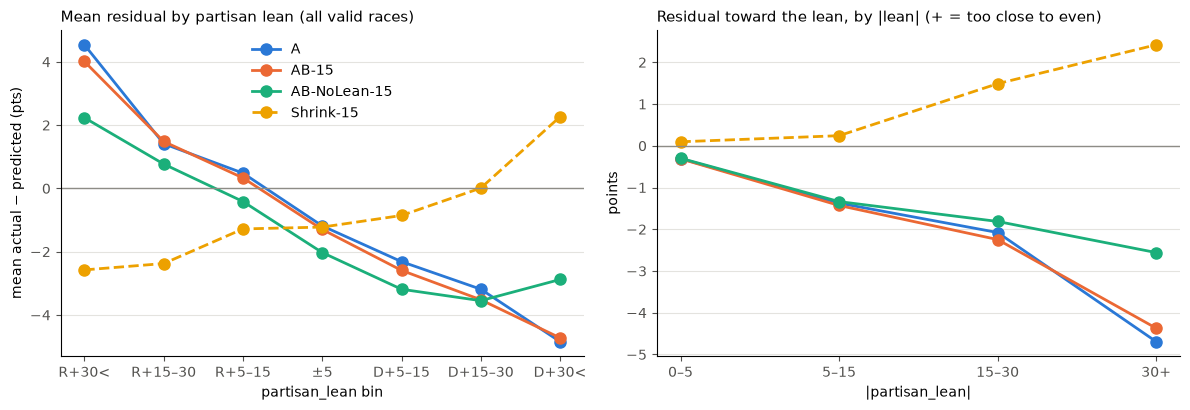

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(LEAN_LABELS))
for m in COLORS:
    axes[0].plot(x, signed[m], STYLES[m], color=COLORS[m], lw=2, marker="o", ms=8, label=m)
axes[0].set_xticks(x, LEAN_LABELS)
axes[0].axhline(0, color="#8d8c86", lw=1)
tidy(axes[0], "Mean residual by partisan lean (all valid races)", "partisan_lean bin", "mean actual − predicted (pts)")
axes[0].legend(frameon=False)
x = np.arange(len(MAGNITUDE_LABELS))
for m in COLORS:
    axes[1].plot(x, magnitude[("mean residual × sign(lean)", m)], STYLES[m], color=COLORS[m], lw=2, marker="o", ms=8)
axes[1].set_xticks(x, MAGNITUDE_LABELS)
axes[1].axhline(0, color="#8d8c86", lw=1)
tidy(axes[1], "Residual toward the lean, by |lean| (+ = too close to even)", "|partisan_lean|", "points")
plt.tight_layout()

## 7. Residuals by election year and state

- **National directional error:** each year's mean residual, shared by every district that year.
- **Decomposition:** the mean squared residual splits exactly into three parts. *National* is the year mean², *state* is the state-year mean minus the year mean, squared, and *district* is the residual minus its state-year mean, squared. All are averaged over races. At-large states have one district per year, so their deviations fall entirely in *state*.
- **States:** the states, with at least 12 scored district-years, whose mean residual moves most between AB-15 and AB-NoLean-15.

In [15]:
yearly = pd.concat({"mean residual (bias)": RESID.groupby(races["year"]).mean(),
                    "MAE": RESID.abs().groupby(races["year"]).mean()}, axis=1)
display(Markdown("### By eval year (all valid races)"))
display(yearly.style.format(precision=2))
yearly_bias = pd.concat({section: RESID[mask].groupby(races.loc[mask, "year"]).mean()[["A", "AB-15", "AB-NoLean-15",
                                                                                      "Shrink-15", "B-NoLean"]]
                         for section, mask in MASKS.items()}, axis=1)
display(Markdown("### Mean residual (bias) by eval year and subset"))
display(yearly_bias.style.format(precision=2))

year_mean = RESID.groupby(races["year"]).transform("mean")
state_year_mean = RESID.groupby([races["year"], races["state"]]).transform("mean")
decomposition = pd.DataFrame({"MSE": (RESID ** 2).mean(), "national": (year_mean ** 2).mean(),
                              "state": ((state_year_mean - year_mean) ** 2).mean(),
                              "district": ((RESID - state_year_mean) ** 2).mean()})
assert np.allclose(decomposition["MSE"], decomposition[["national", "state", "district"]].sum(axis=1))
for part in ["national", "state", "district"]:
    decomposition[f"{part} %"] = 100 * decomposition[part] / decomposition["MSE"]
display(Markdown("### Mean squared residual: national, state, and district parts (all valid races)"))
display(decomposition.style.format(precision=2))

state_n = races.groupby("state").size()
state_mean = RESID.groupby(races["state"]).mean()[state_n >= 12]
state_mean["n"] = state_n
state_mean["NoLean − AB-15"] = state_mean["AB-NoLean-15"] - state_mean["AB-15"]
display(Markdown("### States whose mean residual moves most from AB-15 to AB-NoLean-15 (2018–2024)"))
state_mean.reindex(state_mean["NoLean − AB-15"].abs().sort_values(ascending=False).index).head(10)[
    ["n", "A", "AB-15", "AB-NoLean-15", "Shrink-15", "NoLean − AB-15"]].style.format(precision=2).format({"n": "{:.0f}"})

### By eval year (all valid races)

### Mean residual (bias) by eval year and subset

### Mean squared residual: national, state, and district parts (all valid races)

,MSE,national,state,district,national %,state %,district %
A,49.05,2.55,17.55,28.95,5.20,35.78,59.03
AB-15,43.38,2.51,16.18,24.68,5.80,37.30,56.90
AB-NoLean-15,34.57,2.31,12.69,19.57,6.69,36.69,56.61
Shrink-15,40.31,2.69,11.97,25.65,6.66,29.71,63.63
B,73.31,18.43,16.63,38.24,25.14,22.69,52.16
B-NoLean,234.90,22.84,36.34,175.72,9.72,15.47,74.81


### States whose mean residual moves most from AB-15 to AB-NoLean-15 (2018–2024)

,n,A,AB-15,AB-NoLean-15,Shrink-15,NoLean − AB-15
state,,,,,,
AL,19,3.938360,3.126124,1.185175,-1.833795,-1.940949
KS,16,6.902976,6.311911,4.642098,2.828683,-1.669813
KY,22,4.680929,4.116908,2.460812,-0.783863,-1.656095
TN,35,3.571997,2.906224,1.294439,-1.407244,-1.611785
OK,19,7.556603,7.382836,5.787552,0.857029,-1.595284
AR,15,0.650824,0.258190,-1.123465,-4.808068,-1.381655
NE,12,1.093035,0.601507,-0.737212,-3.595508,-1.338719
IN,36,2.563398,2.409956,1.408081,-0.993764,-1.001875
IA,16,1.043269,0.775467,-0.177105,-0.785254,-0.952573


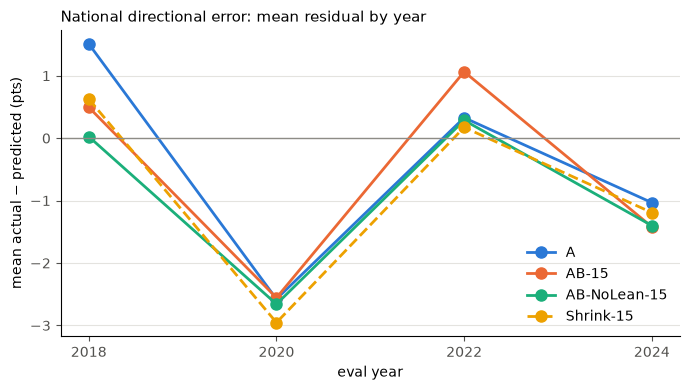

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for m in COLORS:
    ax.plot(EVAL_YEARS, yearly[("mean residual (bias)", m)], STYLES[m], color=COLORS[m], lw=2, marker="o", ms=8, label=m)
ax.set_xticks(EVAL_YEARS)
ax.axhline(0, color="#8d8c86", lw=1)
tidy(ax, "National directional error: mean residual by year", "eval year", "mean actual − predicted (pts)")
ax.legend(frameon=False)
plt.tight_layout()

## 8. Where does the gain come from: safe or competitive races?

Valid races are split into three exclusive groups: ex-ante competitive, ex-post competitive only (a surprise close race), and safe (neither). For each ensemble, the table shows the change in MAE versus A within each group, and each group's share of the total change in absolute error (pooled, 2018–2024). A negative change is an improvement.

In [17]:
group = np.select([races["competitive_ex_ante"], races["competitive_ex_post"]],
                  ["ex-ante competitive", "ex-post only"], "safe")
abs_change = RESID[ENSEMBLES].abs().sub(RESID["A"].abs(), axis=0)
gain = {}
for m in ENSEMBLES:
    total = abs_change[m].sum()
    for g in ["ex-ante competitive", "ex-post only", "safe"]:
        rows = group == g
        gain[(m, g)] = {"n": int(rows.sum()), "MAE A": RESID.loc[rows, "A"].abs().mean(),
                        "MAE model": RESID.loc[rows, m].abs().mean(), "ΔMAE": abs_change.loc[rows, m].mean(),
                        "Σ Δ|residual|": abs_change.loc[rows, m].sum(),
                        "share of total Δ (%)": 100 * abs_change.loc[rows, m].sum() / total}
pd.DataFrame.from_dict(gain, orient="index").rename_axis(["model", "group"]).style.format(precision=2).format(
    {"n": "{:.0f}"})

### Paired comparison of AB-NoLean-15 with AB-15 and Shrink-15

On the same races: the mean change in absolute error (negative favors AB-NoLean-15), its naive standard error (races treated as independent, so it is optimistic), the share of races where AB-NoLean-15 is closer, and the number of eval years (of 4) whose MAE favors it.

In [18]:
paired = {}
for other in ["AB-15", "Shrink-15"]:
    diff = RESID["AB-NoLean-15"].abs() - RESID[other].abs()
    for section, mask in MASKS.items():
        d = diff[mask]
        per_year = d.groupby(races.loc[mask, "year"]).mean()
        paired[(other, section)] = {"n": len(d), "mean Δ|residual|": d.mean(), "naive se": d.std() / np.sqrt(len(d)),
                                    "% races closer": 100 * (d < 0).mean(), "years favoring NoLean": int((per_year < 0).sum())}
pd.DataFrame.from_dict(paired, orient="index").rename_axis(["vs", "subset"]).style.format(precision=3).format(
    {"n": "{:.0f}", "years favoring NoLean": "{:.0f}", "% races closer": "{:.1f}"})

## 9. Shrinkage or complementary information?

AB-NoLean-15 moves A's prediction by 0.15 × (B-NoLean − A). Shrink-15 moves it by −0.15 × (A's lean terms). If the first adjustment is mostly the second, a regression of one on the other has slope ≈ 1 and a high R², and whatever is left over is what the fundamentals add. The same regression is shown for AB-15. The last column checks whether the leftover part helps: it is the MAE of A plus the leftover alone, without the shrinkage.

In [19]:
shrink_move = PRED["Shrink-15"] - PRED["A"]
rows = {}
for m in ["AB-15", "AB-NoLean-15"]:
    move = PRED[m] - PRED["A"]
    for section, mask in MASKS.items():
        fit = smf.ols("move ~ shrink", data=pd.DataFrame({"move": move[mask], "shrink": shrink_move[mask]})).fit()
        leftover = fit.resid + fit.params["Intercept"]  # the part of the move not proportional to the shrinkage
        rows[(m, section)] = {"slope on shrink move": fit.params["shrink"], "R²": fit.rsquared,
                              "sd(move)": move[mask].std(), "sd(leftover)": leftover.std(),
                              "MAE A": RESID.loc[mask, "A"].abs().mean(),
                              "MAE A + leftover": (races.loc[mask, "actual_margin"] - PRED.loc[mask, "A"] - leftover).abs().mean(),
                              "MAE model": RESID.loc[mask, m].abs().mean()}
pd.DataFrame.from_dict(rows, orient="index").rename_axis(["model", "subset"]).style.format(precision=3)

## Conclusion

**Verdict:** removing partisan lean from B mostly corrects a structural flaw in Model A, adds a small amount of competitive-race information, and introduces a Democratic-ward bias in competitive races. AB-NoLean-15 should **not replace AB-15**. The diagnostic worth following up is A's over-extension in safe seats, not the lean-free B.

**1. Headline numbers.** AB-NoLean-15 beats AB-15 in every subset and every eval year (pooled MAE):

| subset | A | AB-15 | AB-NoLean-15 |
|---|---|---|---|
| ex-ante competitive | 4.85 | 4.57 | 4.41 |
| ex-post competitive | 6.18 | 5.74 | 5.33 |
| all districts | 5.36 | 5.07 | 4.53 |

The equal-year averages tell the same story. On winner calls, AB-NoLean-15 nets +4 against A (8 fixed, 4 broken), while AB-15 nets +2. That is two more correct calls in four elections. Three of AB-NoLean-15's four net gains come from 2018, and it nets 0 in both 2022 and 2024.

**2. Most of the gain is in safe seats.** About 81% of the total reduction in absolute error comes from safe districts; ex-ante competitive races supply 12%.

- **A over-extends lopsided districts.** Its residual toward the lean is −4.7 points where |lean| ≥ 30: it predicts them too far from even.
- **B-NoLean errs the opposite way** (+9.5 points: far too close to even), so the two errors offset.
- That offset is what produces the negative all-district residual correlation between A and B-NoLean (−0.25), against +0.41 for A and B. It is an offset of opposite structural errors, not independent information.

**3. Shrinkage explains much of the gain, but not all of it.**

- **Ex-post competitive: pure shrinkage.** Shrink-15 does as well as AB-NoLean-15 (MAE 5.23 vs 5.33; AB-NoLean-15 is worse in 2 of 4 years). The shrinkage move explains 62% of AB-NoLean-15's move (slope 0.91), and the leftover part doesn't improve MAE at all (6.18 → 6.18).
- **All districts: partly shrinkage.** Shrink-15 recovers about half of the gain (−0.46 of −0.83). The rest is a nonlinear correction concentrated in the safest seats, which uniform linear shrinkage can't mimic: Shrink-15 overshoots there and flips the residual's sign in both 30+ bins.
- **Ex-ante competitive: not shrinkage.** Shrink-15 gains almost nothing here (−0.03), the shrinkage move explains only 6% of AB-NoLean-15's move, and the leftover carries the whole gain (4.85 → 4.44). This is the only real evidence of complementary information. Against AB-15 it is −0.16 MAE (naive standard error 0.06), it holds in 4 of 4 years, and AB-NoLean-15 is closer in 55% of races.

**4. The competitive-race gain comes with a Democratic-ward bias.** A negative residual means the model was too Democratic.

- **Pooled bias:** in ex-ante competitive races AB-NoLean-15's bias is −1.46, against −0.67 for AB-15 and −0.47 for A; in ex-post races it is −1.19 against −0.34.
- **By year:** AB-NoLean-15 is more Democratic-biased than AB-15 in the ex-ante competitive races of 2020, 2022, and 2024. The shift helped only in 2018, when A was too Republican.
- **Calls:** every competitive call it changed moved from R to D.
- **Lean bins:** residuals in the ±5 and D+5–15 bins become more negative.
- **B-NoLean alone is not a credible fundamentals model:**
  - its ex-ante bias is −7.1 and its MAE is 9.2 (12.1 over all districts)
  - its inflation coefficient flips sign relative to B (+0.12 vs −0.44)
  - its midterm penalty is unstable: −3.4 in the 2018 window, then about −1.3
  - its value comes only from offsetting A's errors

**5. Tails and dispersion.** AB-NoLean-15 has fewer large errors:

- **Misses over 10 points:** 8.1% of races, against 11.4% for AB-15 and 13.8% for A.
- **Misses over 20 points:** 0.56%, against 0.94% for AB-15.

Skewness and excess kurtosis barely change. Compared with AB-15, the reduction is in the state and district parts of the squared error; the national part is unchanged.

**Recommendation.** Keep AB-15 (`house_ensemble_ab_85_15`) as the Stage 1 ensemble.

- **Why not switch:** AB-NoLean-15's edge in competitive races is small (−0.16 ex-ante MAE and 2 calls in four elections, mostly 2018). It comes with a systematic Democratic-ward shift in competitive races, and through a component that is not interpretable on its own.
- **What to follow up instead:** the larger and cleaner finding is that Model A over-extends partisan lean in safe districts. That belongs in a separate, pre-specified check of A's lean specification, which could capture the safe-seat gain without B-NoLean's bias.
- **When to revisit:** only if the no-lean ex-ante gain persists once A's safe-seat over-extension is addressed.
- **Evidence base:** four elections, all previously examined (including 2024), so every difference here is development evidence, not a confirmatory test.